First 5 rows:
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   Pedigree  Age  Outcome  
0     0.627   50        1  
1     0.351   31        0  
2     0.672   32        1  
3     0.167   21        0  
4     2.288   33        1  

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Pregnancies    768 non-null    int64  
 1   Glucose        768 non-null    int64  
 2   BloodPressure  768 non-null    int64  
 3   SkinThickness  768 non-null    int

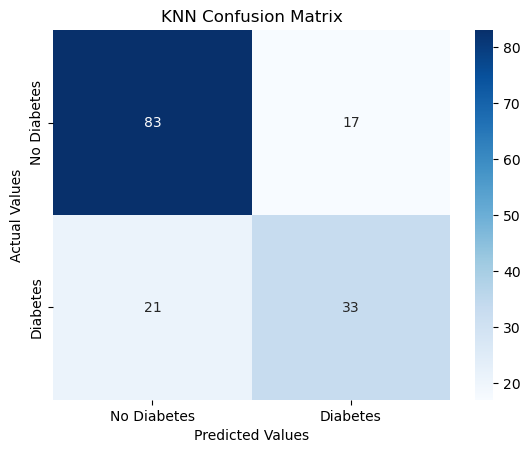


===== KNN PERFORMANCE =====
Accuracy: 0.7532467532467533
Error Rate: 0.24675324675324672
Precision: 0.66
Recall: 0.6111111111111112

===== RESULTS IN PERCENTAGE =====
Accuracy: 75.32467532467533 %
Error Rate: 24.675324675324674 %
Precision: 66.0 %
Recall: 61.111111111111114 %

Prediction: Diabetes


In [5]:
# ==========================================
# 1. IMPORT REQUIRED LIBRARIES
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score
)

# ==========================================
# 2. LOAD DATASET
# ==========================================

df = pd.read_csv("diabetes.csv")

print("First 5 rows:")
print(df.head())

print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

# ==========================================
# 3. DATA PREPROCESSING
# ==========================================

# Replace invalid zero values with median
columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

for col in columns:
    df[col] = df[col].replace(0, np.nan)
    df[col] = df[col].fillna(df[col].median())

print("\nDataset after preprocessing:")
print(df.head())

# ==========================================
# 4. SPLIT INPUT AND OUTPUT
# ==========================================

# Input features
X = df.drop("Outcome", axis=1)

# Output variable
y = df["Outcome"]

# ==========================================
# 5. SPLIT TRAINING AND TESTING DATA
# ==========================================

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining Data:", X_train.shape)
print("Testing Data:", X_test.shape)

# ==========================================
# 6. FEATURE SCALING
# ==========================================

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# ==========================================
# 7. IMPLEMENT KNN ALGORITHM
# ==========================================

# Create KNN model with K = 5
knn = KNeighborsClassifier(n_neighbors=5)

# Train the model
knn.fit(X_train, y_train)

# Predict test data
y_pred = knn.predict(X_test)

print("\nPredicted Values:")
print(y_pred)

# ==========================================
# 8. CONFUSION MATRIX
# ==========================================

cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

# Display confusion matrix
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Diabetes", "Diabetes"],
    yticklabels=["No Diabetes", "Diabetes"]
)

plt.title("KNN Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.show()

# ==========================================
# 9. CALCULATE PERFORMANCE METRICS
# ==========================================

accuracy = accuracy_score(y_test, y_pred)

error_rate = 1 - accuracy

precision = precision_score(y_test, y_pred)

recall = recall_score(y_test, y_pred)

print("\n===== KNN PERFORMANCE =====")

print("Accuracy:", accuracy)

print("Error Rate:", error_rate)

print("Precision:", precision)

print("Recall:", recall)

# ==========================================
# 10. DISPLAY RESULTS IN PERCENTAGE
# ==========================================

print("\n===== RESULTS IN PERCENTAGE =====")

print("Accuracy:", accuracy * 100, "%")

print("Error Rate:", error_rate * 100, "%")

print("Precision:", precision * 100, "%")

print("Recall:", recall * 100, "%")

# ==========================================
# 11. PREDICT A SAMPLE PATIENT
# ==========================================

sample = X_test[0].reshape(1, -1)

prediction = knn.predict(sample)

if prediction[0] == 1:
    print("\nPrediction: Diabetes")
else:
    print("\nPrediction: No Diabetes")